# Word2Vec

## Script passo-a-passo

In [13]:
!pip install --upgrade --force-reinstall numpy==1.24.4 scipy gensim

  Using cached numpy-2.0.0-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (60 kB)
Using cached numpy-2.0.0-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (19.3 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.0.0 which is incompatible.
tsfresh 0.21.0 requires scipy>=1.14.0; python_version >= "3.10", but you have scipy 1.13.1 which is incompatible.


In [7]:
!pip install lxml
!pip install beautifulsoup4
!pip install gensim

  Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.3 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
tsfresh 0.21.0 requires scipy>=1.14.0; python_version >= "3.10", but you have scipy 1.13.1 which is incompatible.


In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from gensim.models import Word2Vec
import gensim
from gensim.models import Word2Vec

from collections.abc import Mapping

import bs4 as bs
import urllib.request
import re
import nltk

In [4]:
wiki_coleta = urllib.request.urlopen('https://en.wikipedia.org/wiki/Artificial_intelligence')
print('wiki_coleta: ', wiki_coleta)

print('*************************')

conteudo = wiki_coleta.read()
print('conteudo: ', conteudo)

print('*************************')

parsing_artigo = bs.BeautifulSoup(conteudo,'lxml')
# print('parsing_artigo: ', parsing_artigo)

# print('*************************')

paragrafo_artigo = parsing_artigo.find_all('p')
print('paragrafo_artigo: \n\n', paragrafo_artigo)

print('*************************')

texto_artigo = ""
print('texto_artigo: \n\n', type(texto_artigo))

print('*************************')


for p in paragrafo_artigo:
    texto_artigo += p.text

print('texto_artigo: \n\n', texto_artigo)

print('*************************')

wiki_coleta:  <http.client.HTTPResponse object at 0x7cac7e266710>
*************************
conteudo:  b'<!DOCTYPE html>\n<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 vector-feature-night-mode-enabled skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-available" lang="en" dir="ltr">\n<head>\n<meta charset="UTF-8">\n<title>Artificial intelligence - Wikipedia</title>\n<script>(function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-

In [5]:
texto_artigo

'\nArtificial intelligence (AI) is the capability of computational systems to perform tasks typically associated with human intelligence, such as learning, reasoning, problem-solving, perception, and decision-making. It is a field of research in computer science that develops and studies methods and software that enable machines to perceive their environment and use learning and intelligence to take actions that maximize their chances of achieving defined goals.[1]\nHigh-profile applications of AI include advanced web search engines (e.g., Google Search); recommendation systems (used by YouTube, Amazon, and Netflix); virtual assistants (e.g., Google Assistant, Siri, and Alexa); autonomous vehicles (e.g., Waymo); generative and creative tools (e.g., ChatGPT and AI art); and superhuman play and analysis in strategy games (e.g., chess and Go). However, many AI applications are not perceived as AI: "A lot of cutting edge AI has filtered into general applications, often without being called

In [6]:
from nltk.tokenize import word_tokenize
from nltk.tokenize import sent_tokenize
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

artigo_preproc = texto_artigo.lower()
artigo_preproc = re.sub('[^a-zA-Z]', ' ', artigo_preproc)
print(artigo_preproc)
artigo_preproc = re.sub(r'\s+', ' ', artigo_preproc)
print(artigo_preproc)

frases = nltk.sent_tokenize(artigo_preproc)
print('Token no nível de frase: ', frases)
palavras_token = [nltk.word_tokenize(sent) for sent in frases]
print('Token no nível de palavras - com Stopwords: ', palavras_token)


from nltk.corpus import stopwords
for i in range(len(palavras_token)):
    palavras_token[i] = [w for w in palavras_token[i] if w not in stopwords.words('english')]

print('Token no nível de palavras - sem Stopwords: ', palavras_token)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


 artificial intelligence  ai  is the capability of computational systems to perform tasks typically associated with human intelligence  such as learning  reasoning  problem solving  perception  and decision making  it is a field of research in computer science that develops and studies methods and software that enable machines to perceive their environment and use learning and intelligence to take actions that maximize their chances of achieving defined goals     high profile applications of ai include advanced web search engines  e g   google search   recommendation systems  used by youtube  amazon  and netflix   virtual assistants  e g   google assistant  siri  and alexa   autonomous vehicles  e g   waymo   generative and creative tools  e g   chatgpt and ai art   and superhuman play and analysis in strategy games  e g   chess and go   however  many ai applications are not perceived as ai   a lot of cutting edge ai has filtered into general applications  often without being called ai

In [7]:
# meu_word2vec = Word2Vec(palavras_token, min_count=2)
meu_word2vec = gensim.models.Word2Vec(palavras_token,
                                      min_count =3,
                                      workers=4,
                                      vector_size = 100,
                                      window = 10)

In [8]:
meu_word2vec.wv.most_similar('artificial')

[('ai', 0.9852602481842041),
 ('intelligence', 0.9828982949256897),
 ('human', 0.9819157123565674),
 ('models', 0.9816092848777771),
 ('data', 0.9807853698730469),
 ('use', 0.9800180792808533),
 ('technology', 0.9800046682357788),
 ('mind', 0.9796032905578613),
 ('research', 0.9790499210357666),
 ('may', 0.9789665341377258)]

In [9]:
print("Similaridade entre 'artificial' " +
      "e 'intelligence': ",
      meu_word2vec.wv.similarity('artificial', 'intelligence'))


print("Similaridade entre 'artificial' " +
      "e 'logic': ",
      meu_word2vec.wv.similarity('artificial', 'logic'))


print("Similaridade entre 'intelligence' " +
      "e 'problem': ",
      meu_word2vec.wv.similarity('intelligence', 'problem'))



Similaridade entre 'artificial' e 'intelligence':  0.98289824
Similaridade entre 'artificial' e 'logic':  0.9694405
Similaridade entre 'intelligence' e 'problem':  0.97653484


In [10]:
vocabulario_vetores = meu_word2vec.wv.vectors
vocabulario_vetores

array([[-2.63384581e-02,  5.99598214e-02,  1.71326119e-02, ...,
        -1.12200454e-01, -1.96647588e-02, -4.27684281e-03],
       [-2.68710814e-02,  4.56467792e-02,  1.37614710e-02, ...,
        -7.60081038e-02, -2.30192263e-02, -2.55654147e-03],
       [-1.24468869e-02,  3.18917818e-02, -7.47630140e-04, ...,
        -5.00000343e-02, -1.83038262e-03, -1.23421652e-02],
       ...,
       [ 7.03181233e-03,  1.49181811e-02,  5.62750847e-06, ...,
        -5.59151405e-04, -8.22875556e-03, -6.81987964e-03],
       [-8.12898576e-03, -3.77757754e-03,  2.26257811e-03, ...,
        -6.05816022e-03, -4.19258000e-03, -4.29155026e-03],
       [ 4.64360183e-03,  4.51036356e-03,  6.13727141e-03, ...,
         5.07857185e-04,  6.72918418e-03, -6.30286522e-03]], dtype=float32)

In [11]:
vetor_palavra_artificial = meu_word2vec.wv['artificial']
print(f'\n\nImprimindo a palavra \'artificial\' vetorizada: \n\n{vetor_palavra_artificial}')



Imprimindo a palavra 'artificial' vetorizada: 

[-0.0231477   0.03623006  0.00608759  0.00131329 -0.00486456 -0.0898829
  0.0362532   0.10727466 -0.03499014 -0.03373194 -0.03976596 -0.05061369
 -0.00148019 -0.00926474  0.01247675 -0.06788379 -0.01201026 -0.06735709
 -0.02139006 -0.10261383  0.01728634  0.02717921  0.03775728 -0.01171227
 -0.04269101 -0.00506192 -0.03161503 -0.05260764 -0.04462598  0.02928097
  0.04599491 -0.0005514   0.00443593 -0.02181933 -0.03274552  0.06704529
 -0.00924737 -0.04342939 -0.02194051 -0.09967664  0.00187834 -0.06429599
 -0.01324687 -0.01254908  0.05340873 -0.04078857 -0.03299524 -0.01666631
  0.01729853  0.02906452  0.02194249 -0.0525681  -0.00894469  0.00736197
 -0.04662351  0.04562247  0.03512564 -0.00522184 -0.05068029  0.02391287
  0.03019118  0.01159904 -0.00660227 -0.05054294 -0.06276583  0.02877773
  0.05137816  0.05336737 -0.07784482  0.03469716 -0.03081166  0.01139585
  0.03868078 -0.00985517  0.04550705  0.03924466 -0.01124    -0.00556201
 -

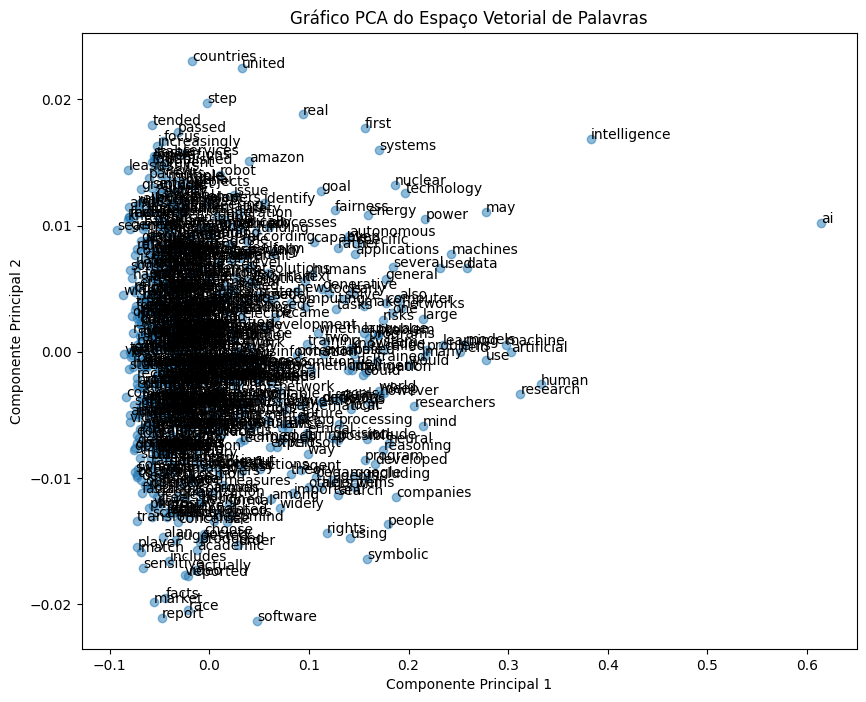

In [12]:
words = list(meu_word2vec.wv.index_to_key)
vectors = [meu_word2vec.wv[word] for word in words]

pca = PCA(n_components=2)  # Escolha o número de componentes principais desejado
vectors_pca = pca.fit_transform(vectors)


plt.figure(figsize=(10, 8))
plt.scatter(vectors_pca[:, 0], vectors_pca[:, 1], alpha=0.5)

for i, word in enumerate(words):
    plt.annotate(word, xy=(vectors_pca[i, 0], vectors_pca[i, 1]), fontsize=10)

plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.title("Gráfico PCA do Espaço Vetorial de Palavras")
plt.show()